In [1]:
import stat_utils as su
import pandas as pd

# Data Creation:

For the following recreation of the results of the paper "Post Processing Recommender Systems with Knowledge Graphs for Recency, Popularity, and Diversity of Explanations" (https://dl.acm.org/doi/pdf/10.1145/3477495.3532041) the PGPR-model has been retrained 5 times per dataset following these steps:
## ML1M
The preprocessed dataset was used to retrain the PGPR-model following the steps from the "Reinforcement Knowledge Graph Reasoning for Explainable Recommendation" papers github page (https://github.com/orcax/PGPR). For the parameters used during each step the parameters found in the log files of the precomputed transe embeddings from the original github repository (https://github.com/giacoballoccu/explanation-quality-recsys) were used. Because of limited time and computation power the knowledge graph embeddings were trained once, the RL agent was trained for the first 2 runs and the evaluation/path extraction was run 5 times using a unique seed for every run including the default seed, which should in theory yield the same results as the numbers reported in the paper, but this is not the case. 

## LASTFM 
Running the knowledge graph embedding training resulted in mapping issues, which is why the trained transe embeddings were taken from the original github repository. Following this again because of limited time and computation power the RL agent was trained once and the evaluation/path extraction was run 5 times with different seeds, which again included the default seed that lead to different results as in the paper.

## Optimization
Optimization was run following the guide from the original github repository with standard parameters (prediction paths: 25-50-1). The resulting files including all 12 runs can be also found here: https://drive.google.com/drive/folders/12YEf0vn3T4ymtl_21XpjNVAeeiB1VBvV (~6 GB).

Note that these include also the "out of the box" results (ootb), which give questionable results and will therefore not be included in the statistical analysis and recreation of the result tables included in the paper.



# Importing Data:

In [2]:
base_dir = './PGPR_model_results/' # directory where the results are stored

datasets = ['ml1m', 'lastfm'] # datasets to be analyzed

combined_df_avg = su.load_all_avg_datasets(base_dir, datasets)


In [3]:
combined_cleaned_avg_df = su.clean_results_avg(combined_df_avg)

# Recreating Figure 2:

Figure 2 reports the percentual changes of NDCG and explanation quality with the proposed reranking approaches for alphas 0.1 to 0.5. Reconstructing this for our 5 runs per dataset leads to the following results:

In [4]:
optimizations = ["ETDopt", "LIRopt", "SEPopt"]
percentual_changes_df = su.calculate_percentual_change(combined_cleaned_avg_df, optimizations)
percentual_changes_df.head()

,dataset_name,run_id,alpha,metric,opt,percentage_increase
0,ml1m,Run 1,0.0,ndcg,ETDopt,-0.340988
1,ml1m,Run 1,0.0,ndcg,LIRopt,0.000000
2,ml1m,Run 1,0.0,ndcg,SEPopt,0.000000
3,ml1m,Run 1,0.0,LIR,ETDopt,0.066889
4,ml1m,Run 1,0.0,LIR,LIRopt,-1.420249


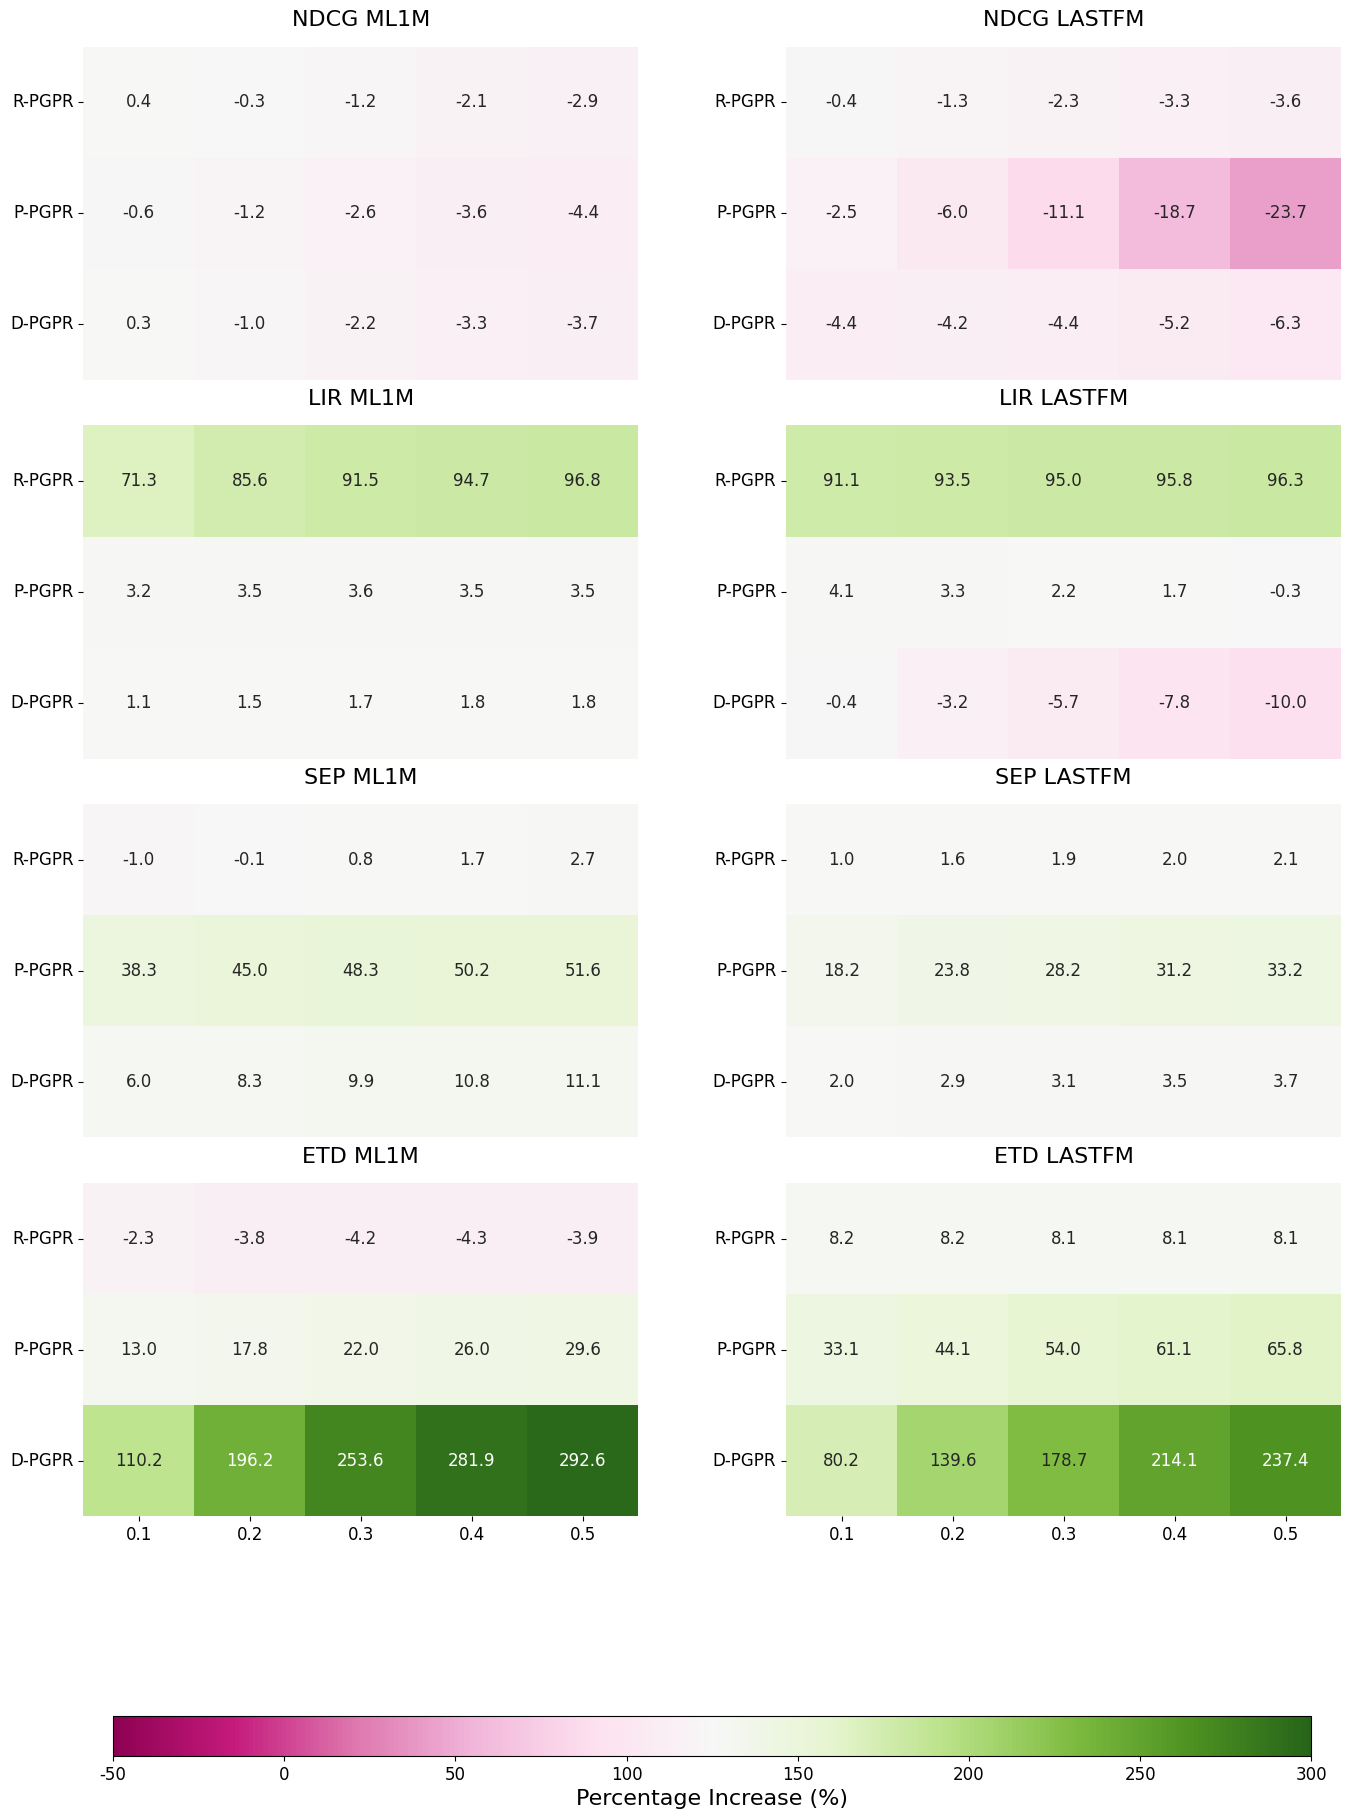

In [5]:
su.plot_all_heatmaps(percentual_changes_df, agg_method="avg", show=True)

The currently shown values include the average of the percentual changes over all runs per dataset. Interestingly the ndcg changes are not that drastic especially for P-PGPR. For the LIR R-PGPR yields lower increases for ML1M, but higher increases for LASTFM. Also the change in LIR for D-PGPR is way higher as reported in the paper. SEP increases for P-PGPR are significantly lower for our runs in comparison to the papers results. ETD increases for D-PGPR are more than double the amount higher as in the paper for the ML1M dataset and in a similar range for the LASTFM dataset. 

# Recreating Table 3:

Table 3 reports the recommendation utility for all model optimizations in comparison to some baseline models. Again because of time and computation power additional baseline models were only run one time to recreate the table and can be found here: https://github.com/giacoballoccu/Knowlede-Aware-Recommender-Systems-Baselines.

But the more interesting thing about this and the following tables is that they are only created for a value of alpha with these conditions: "We selected the values of 𝛼 for our approaches, assuming to work in a context where the platform owners are willing to lose 10% of NDCG at most to increase as much as possible the quality of the explanations, according to the three proposed properties."

These are pretty vague instructions for the purpose of recreating the results, but with the additionally stated numbers in the text and the results of Table 2 one can figure out that the selected alphas for R-PGPR, P-PGPR and D-PGPR look like this:
- R-PGPR: ml1m: 0.2, lastfm: 0.2 
- P-PGPR: ml1m: 0.1, lastfm: 0.1
- D-PGPR: ml1m: 0.5, lastfm: 0.5

An interpretation of all of this vaguely gets us to the criteria for alpha selection of: "Select alpha, where ndcg decreases are smaller than 10% and targeted explanation quality increases by roughly more than 5% for increasing alphas." 
With these criteria we tried to select the most used alpha over all runs per optimization and continued with this value for the recreation of the other tables.

In [6]:
optimizations_all = combined_cleaned_avg_df["opt"].unique()
percentual_changes_all_df = su.calculate_percentual_change(combined_cleaned_avg_df, optimizations_all)

best_alphas = su.find_best_alpha(percentual_changes_all_df, ndcg_threshold=-10, min_explanation_increase=5, return_most_used_alpha=True)
best_alphas

,opt,alpha,dataset_name
0,ETD_LIR_opt,0.5,lastfm
1,ETD_SEP_LIR_opt,0.2,lastfm
2,ETD_SEP_opt,0.1,lastfm
3,ETDopt,0.5,lastfm
4,LIRopt,0.1,lastfm
5,SEP_LIR_opt,0.1,lastfm
6,SEPopt,0.2,lastfm
7,ETD_LIR_opt,0.4,ml1m
8,ETD_SEP_LIR_opt,0.3,ml1m
9,ETD_SEP_opt,0.3,ml1m


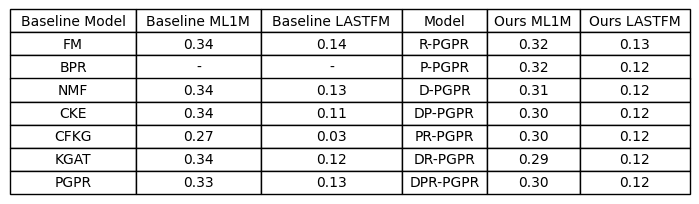

In [7]:
extracted_data_avg = su.extract_data_with_most_used_alpha_avg(combined_cleaned_avg_df, best_alphas, only_overall=True)
final_ndcg_table = su.create_ndcg_table(extracted_data_avg)
su.plot_ndcg_table(final_ndcg_table)

The results presented here are averaged over all 5 runs for our models and yield similar results to the reported numbers in the paper.

(BPR not run because of missing hyperparameters in the original repository)

# Recreating Table 4:

Table 4 reports the selected explanation qualities and the total explanation quality (EQ) of the different optimizations.

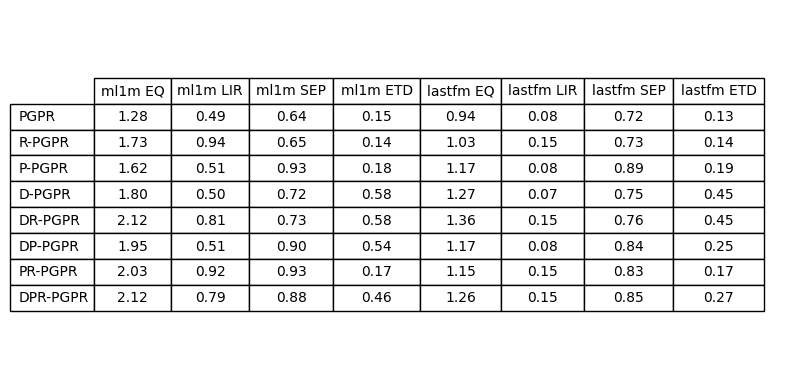

In [8]:
df_table_4 = su.create_explanation_quality_table(extracted_data_avg)
su.plot_explanation_quality_table(df_table_4)

Again this is averaged over all runs and provides completely different results than reported. Total explanation quality is way higher than reported for the ML1M dataset and way lower than reported in the LASTFM dataset. For the ML1M dataset this mainly comes from the way higher SEP values and for the LASTFM dataset the LIR values are significantly lower.

# Recreating Table 5:

Table 5 reports the difference between the NDCG, LIR, SEP and ETD of male and female user groups and their statistical significance. The differences can be easily calculated from the averages but for the statistical significance (p = 0.05) we have to work with the distributions of the results, which will be loaded and cleaned in the following steps.

In [9]:
extracted_data_table_5 = su.extract_data_with_most_used_alpha_avg(combined_cleaned_avg_df, best_alphas, only_overall=False)
clean_tab_5_data = su.clean_table_5_data(extracted_data_table_5)
clean_tab_5_data.head()

,alpha,metric,opt,run_id,dataset_name,group,data
260,0.5,ETD,ETD_LIR_opt,Run 1,lastfm,Diff,0.000868
261,0.5,ETD,ETD_LIR_opt,Run 2,lastfm,Diff,0.007700
262,0.5,ETD,ETD_LIR_opt,Run 3,lastfm,Diff,0.006259
263,0.5,ETD,ETD_LIR_opt,Run 4,lastfm,Diff,0.004910
264,0.5,ETD,ETD_LIR_opt,Run 5,lastfm,Diff,0.003804


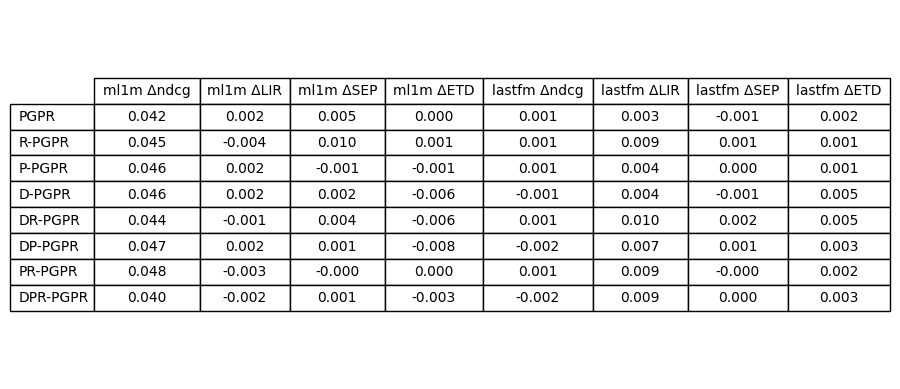

In [10]:
table_5_df = su.create_delta_explanation_table(clean_tab_5_data)
su.plot_fairness_table(table_5_df,round = True)

The raw table without significance testing can be seen above. For this the difference of the groups per run got taken and then again averaged to produce the table. The differences are all in all lower for the LASTFM dataset and also for the ML1M dataset with the exception of the NDCG column.

In [11]:
combined_cleaned_df_dist = pd.concat(su.process_all_files(base_dir, datasets), ignore_index=True)
df_dist_extracted = su.extract_data_with_most_used_alpha_dist(combined_cleaned_df_dist,best_alphas)
kruskal_results = su.perform_kruskal_test(df_dist_extracted)

In [12]:
kruskal_results.head()

,opt,run_id,dataset_name,metric,statistic,p_value,significance
0,ETD_LIR_opt,Run 1,lastfm,ETD,0.078820,0.778903,Not Significant
1,ETD_LIR_opt,Run 1,lastfm,LIR,1.828091,0.176353,Not Significant
2,ETD_LIR_opt,Run 1,lastfm,SEP,1.256659,0.262284,Not Significant
3,ETD_LIR_opt,Run 1,lastfm,ndcg,0.103643,0.747501,Not Significant
4,ETD_LIR_opt,Run 1,ml1m,ETD,5.810528,0.015931,Significant


In [13]:
stouffer_results = su.perform_stouffer_test(kruskal_results)
stouffer_results.head()

,opt,dataset_name,metric,significant_runs,not_significant_runs,combined_p_value,overall_significance
0,baseline,lastfm,etd,1,4,0.131895,Not Significant
1,baseline,lastfm,lir,0,5,0.630761,Not Significant
2,baseline,lastfm,ndcg,0,5,0.518309,Not Significant
3,baseline,lastfm,sep,0,5,0.881966,Not Significant
4,baseline,ml1m,etd,0,5,0.347086,Not Significant


After performing the Kruskal-Wallis test (p = 0.05) from the paper per run the results had to be cut down to one p-value per optimization and metric. For this purpose a Stouffer’s test was used to test the significance over all runs.

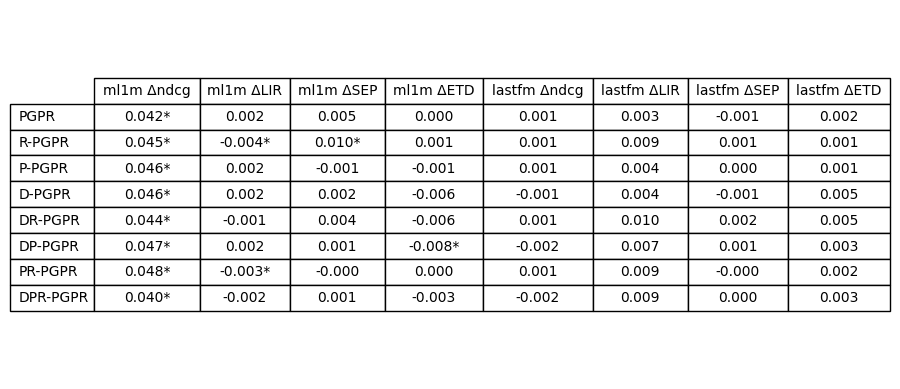

In [14]:
updated_table_5_df = su.mark_significant_values(table_5_df, stouffer_results)
su.plot_fairness_table(updated_table_5_df,round = False)

The resulting significant differences can be seen above, which can be summarized as: There is a significant difference in NDCG for male and female users for all optimizations and also for some optimizations LIR, SEP and ETD values for the ML1M dataset, but no significant differences for the LASTFM dataset. This is also different from the reported numbers, which mark way more results as significant.